# LIBRARIES

In [229]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import StackingClassifier
from xgboost import XGBClassifier

import warnings
warnings.filterwarnings('ignore')

# PREPROCESSING & EDA

In [230]:
df = pd.read_csv('Telco-Customer-Churn.csv')
df_cleaned = df.copy()

In [231]:
df_cleaned.shape

(7043, 21)

In [232]:
df_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [233]:
df_cleaned.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [234]:
df_cleaned.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [235]:
df_cleaned.duplicated().sum()

np.int64(0)

In [236]:
df_cleaned.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [237]:
int_cols = ['tenure', 'TotalCharges', 'MonthlyCharges']

str_cols = ['SeniorCitizen', 'gender', 'Partner', 'Dependents','PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

df_cleaned = df_cleaned[['tenure', 'TotalCharges', 'MonthlyCharges', 'SeniorCitizen', 'gender', 'Partner', 'Dependents','PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn']]

In [238]:
df_cleaned['TotalCharges'] = pd.to_numeric(df_cleaned['TotalCharges'], errors = 'coerce')
df_cleaned['TotalCharges'] =df_cleaned['TotalCharges'].fillna(df_cleaned['TotalCharges'].median())
df_cleaned['TotalCharges'].isnull().sum()

np.int64(0)

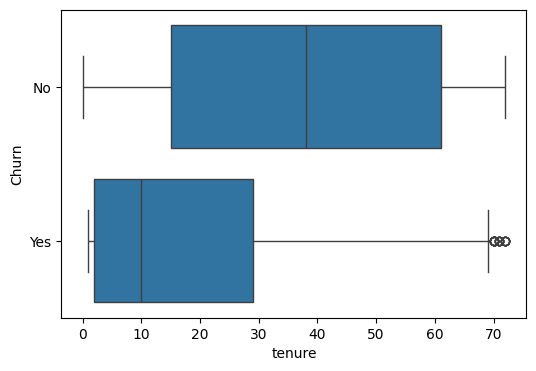

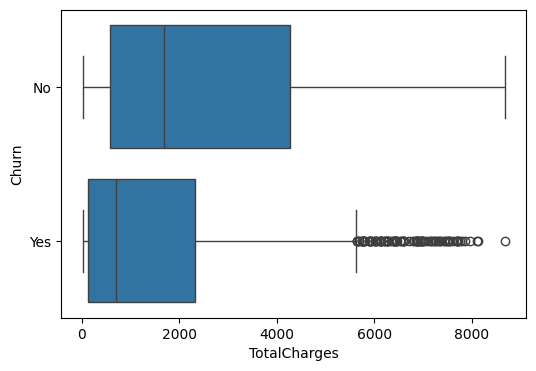

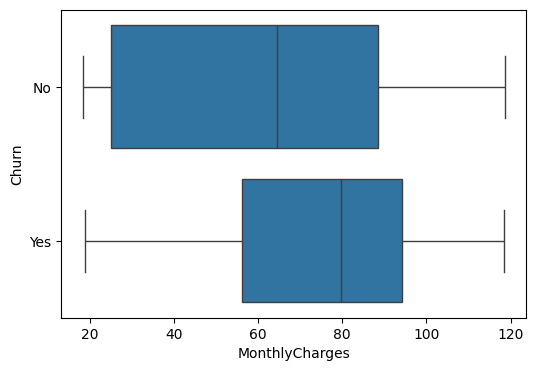

In [239]:
for col in int_cols:
    plt.figure(figsize = (6,4))
    sns.boxplot(data = df_cleaned, x = col, y = 'Churn')

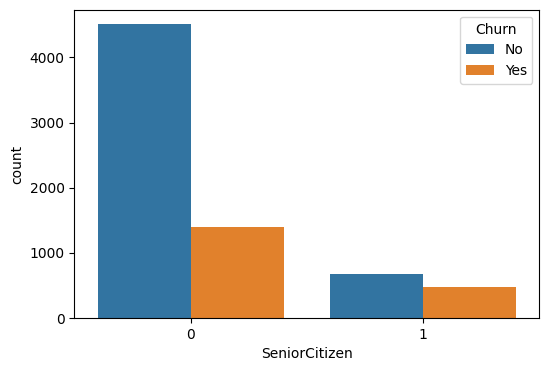

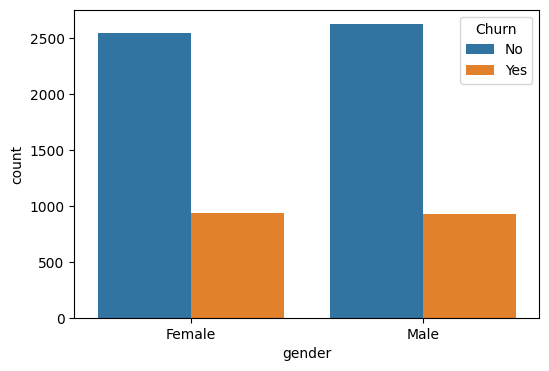

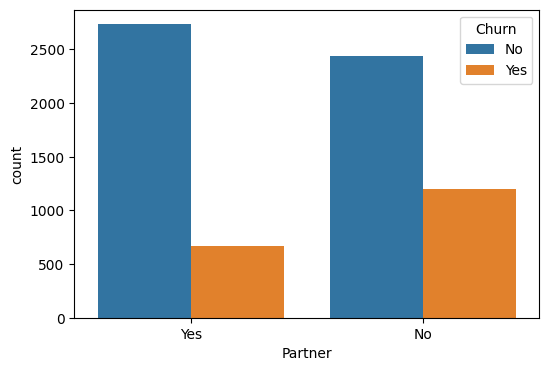

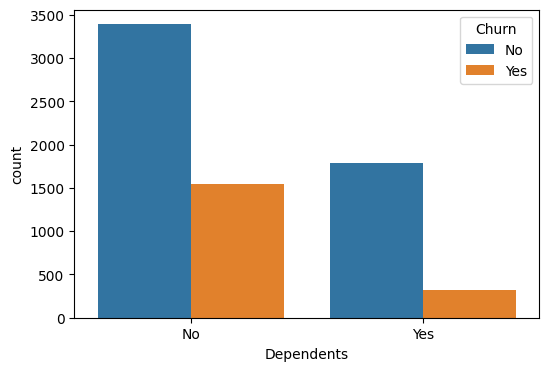

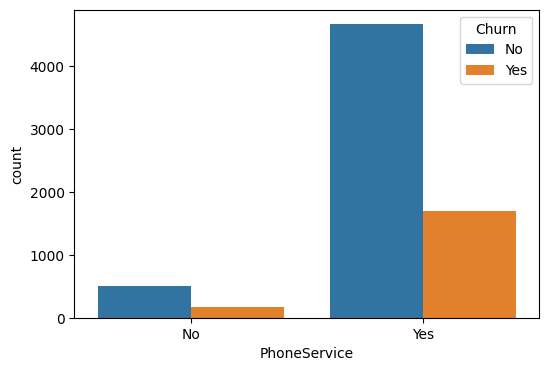

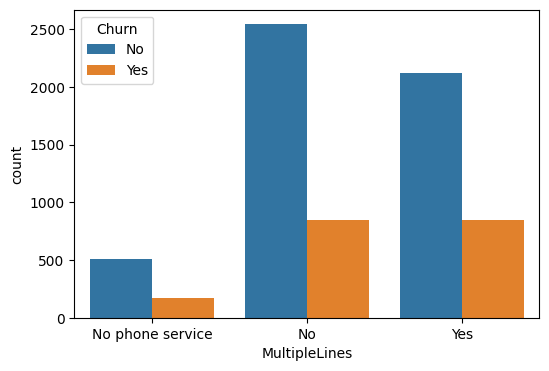

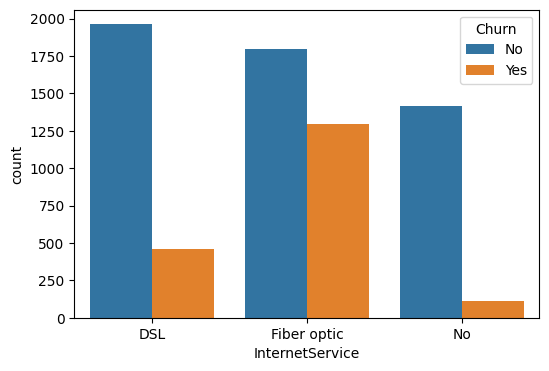

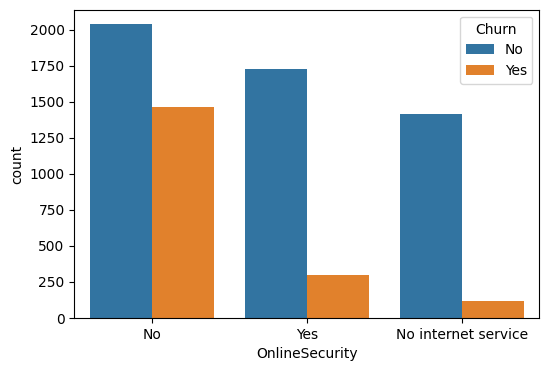

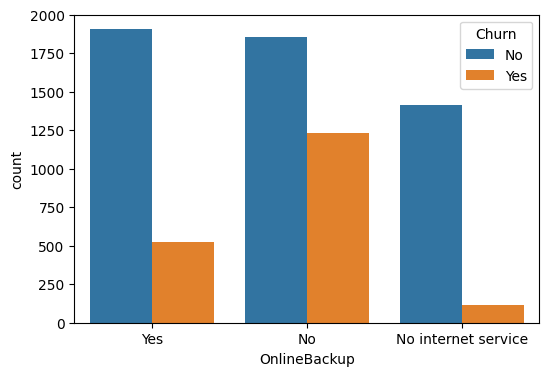

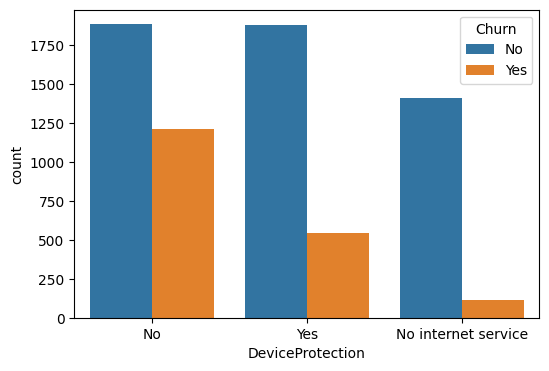

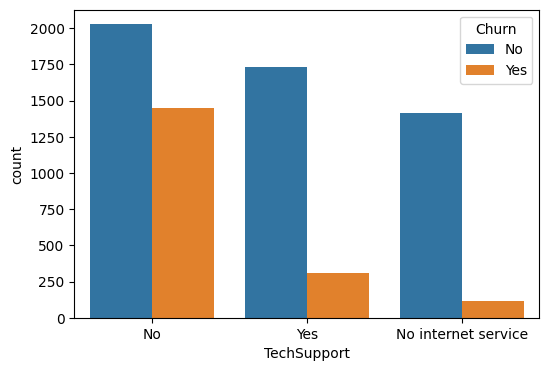

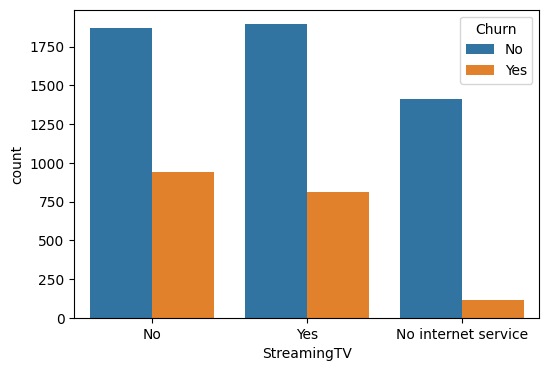

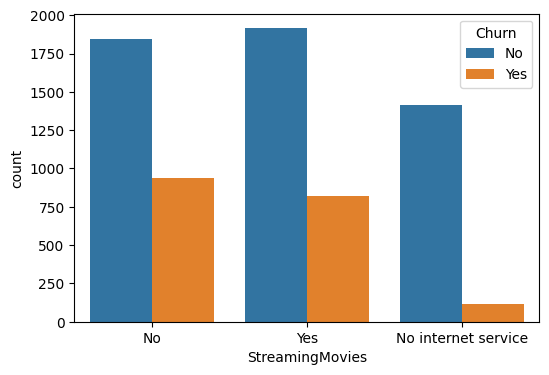

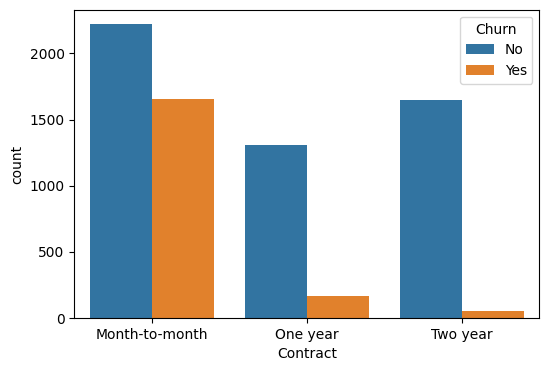

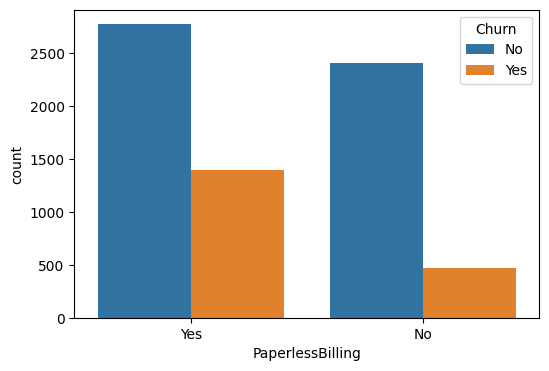

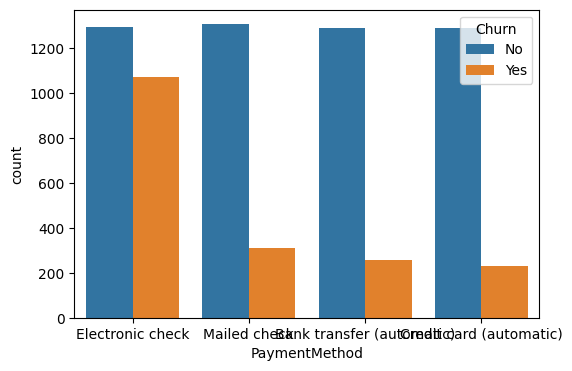

In [240]:
for col in str_cols:
    plt.figure(figsize = (6,4))
    sns.countplot(data = df_cleaned, x = col, hue = 'Churn')

<Axes: >

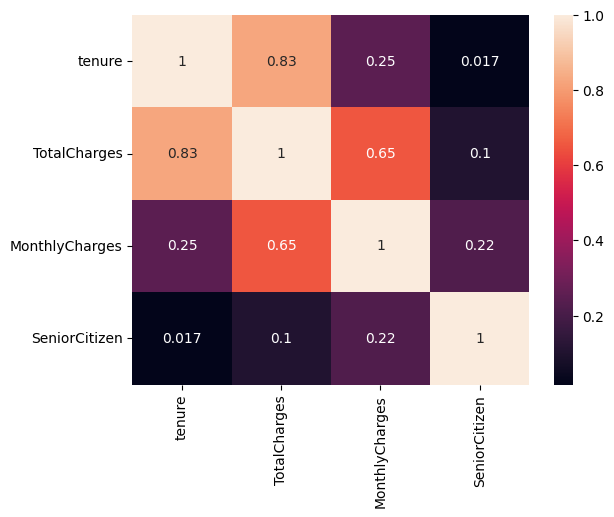

In [241]:
sns.heatmap(df_cleaned.corr(numeric_only=True), annot = True)

In [242]:
dum_df = pd.get_dummies(df_cleaned[str_cols], drop_first = True)
df_cleaned = df_cleaned.drop(str_cols, axis = 1)
df_cleaned = pd.concat([df_cleaned, dum_df], axis = 1)

In [243]:
cat_features = ['gender_Male', 'Partner_Yes', 'Dependents_Yes', 'PhoneService_Yes', 'MultipleLines_No phone service', 'MultipleLines_Yes', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_No internet service', 'OnlineSecurity_Yes', 'OnlineBackup_No internet service', 'OnlineBackup_Yes', 'DeviceProtection_No internet service', 'DeviceProtection_Yes', 'TechSupport_No internet service', 'TechSupport_Yes', 'StreamingTV_No internet service', 'StreamingTV_Yes', 'StreamingMovies_No internet service', 'StreamingMovies_Yes', 'Contract_One year', 'Contract_Two year', 'PaperlessBilling_Yes', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']

In [244]:
df_cleaned[cat_features] = df_cleaned[cat_features].astype(int)

In [245]:
df_cleaned['Churn'] = df_cleaned['Churn'].replace({'No': 0, 'Yes': 1})

In [246]:
df_cleaned

,tenure,TotalCharges,MonthlyCharges,Churn,SeniorCitizen,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,1,29.85,29.85,0,0,0,1,0,0,1,...,0,0,0,0,0,0,1,0,1,0
1,34,1889.50,56.95,0,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,1
2,2,108.15,53.85,1,0,1,0,0,1,0,...,0,0,0,0,0,0,1,0,0,1
3,45,1840.75,42.30,0,0,1,0,0,0,1,...,0,0,0,0,1,0,0,0,0,0
4,2,151.65,70.70,1,0,0,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,24,1990.50,84.80,0,0,1,1,1,1,0,...,0,1,0,1,1,0,1,0,0,1
7039,72,7362.90,103.20,0,0,0,1,1,1,0,...,0,1,0,1,1,0,1,1,0,0
7040,11,346.45,29.60,0,0,0,1,1,0,1,...,0,0,0,0,0,0,1,0,1,0
7041,4,306.60,74.40,1,1,1,1,0,1,0,...,0,0,0,0,0,0,1,0,0,1


In [247]:
df_cleaned.corr()['Churn'].sort_values(ascending=False).reset_index()

,index,Churn
0,Churn,1.000000
1,InternetService_Fiber optic,0.308020
2,PaymentMethod_Electronic check,0.301919
3,MonthlyCharges,0.193356
4,PaperlessBilling_Yes,0.191825
5,SeniorCitizen,0.150889
6,StreamingTV_Yes,0.063228
7,StreamingMovies_Yes,0.061382
8,MultipleLines_Yes,0.040102
9,PhoneService_Yes,0.011942


In [248]:
alpha = 0.05
chi2_result = {}
for col in cat_features:
    contingency = pd.crosstab(df_cleaned[col], df_cleaned['Churn'])
    chi2_stats, p_val, _, _ = chi2_contingency(contingency)
    if p_val < alpha:
        decision = 'Reject Null (Keep Feature)'
    else:
        decision = 'Accept Null (Drop Feature)'
    chi2_result[col] = {'chi2_stats': chi2_stats, 'p_value': p_val, 'decision': decision}

chi2_df = pd.DataFrame(chi2_result).T.sort_values(by = 'p_value')
chi2_df

,chi2_stats,p_value,decision
InternetService_Fiber optic,666.808021,0.0,Reject Null (Keep Feature)
Contract_Two year,641.828115,0.0,Reject Null (Keep Feature)
PaymentMethod_Electronic check,640.557084,0.0,Reject Null (Keep Feature)
DeviceProtection_No internet service,364.519799,0.0,Reject Null (Keep Feature)
TechSupport_No internet service,364.519799,0.0,Reject Null (Keep Feature)
StreamingMovies_No internet service,364.519799,0.0,Reject Null (Keep Feature)
OnlineBackup_No internet service,364.519799,0.0,Reject Null (Keep Feature)
OnlineSecurity_No internet service,364.519799,0.0,Reject Null (Keep Feature)
InternetService_No,364.519799,0.0,Reject Null (Keep Feature)
StreamingTV_No internet service,364.519799,0.0,Reject Null (Keep Feature)


In [249]:
final_df = df_cleaned[['tenure', 'TotalCharges', 'MonthlyCharges', 'InternetService_Fiber optic', 'Contract_Two year', 'PaymentMethod_Electronic check', 'DeviceProtection_No internet service', 'TechSupport_No internet service', 'StreamingMovies_No internet service', 'OnlineBackup_No internet service', 'OnlineSecurity_No internet service', 'InternetService_No', 'StreamingTV_No internet service', 'PaperlessBilling_Yes', 'Contract_One year', 'OnlineSecurity_Yes', 'TechSupport_Yes', 'Dependents_Yes', 'Partner_Yes','PaymentMethod_Credit card (automatic)', 'PaymentMethod_Mailed check','OnlineBackup_Yes', 'DeviceProtection_Yes', 'StreamingTV_Yes','StreamingMovies_Yes', 'MultipleLines_Yes', 'Churn']]

In [250]:
final_df

,tenure,TotalCharges,MonthlyCharges,InternetService_Fiber optic,Contract_Two year,PaymentMethod_Electronic check,DeviceProtection_No internet service,TechSupport_No internet service,StreamingMovies_No internet service,OnlineBackup_No internet service,...,Dependents_Yes,Partner_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Mailed check,OnlineBackup_Yes,DeviceProtection_Yes,StreamingTV_Yes,StreamingMovies_Yes,MultipleLines_Yes,Churn
0,1,29.85,29.85,0,0,1,0,0,0,0,...,0,1,0,0,1,0,0,0,0,0
1,34,1889.50,56.95,0,0,0,0,0,0,0,...,0,0,0,1,0,1,0,0,0,0
2,2,108.15,53.85,0,0,0,0,0,0,0,...,0,0,0,1,1,0,0,0,0,1
3,45,1840.75,42.30,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
4,2,151.65,70.70,1,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,24,1990.50,84.80,0,0,0,0,0,0,0,...,1,1,0,1,0,1,1,1,1,0
7039,72,7362.90,103.20,1,0,0,0,0,0,0,...,1,1,1,0,1,1,1,1,1,0
7040,11,346.45,29.60,0,0,1,0,0,0,0,...,1,1,0,0,0,0,0,0,0,0
7041,4,306.60,74.40,1,0,0,0,0,0,0,...,0,1,0,1,0,0,0,0,1,1


# MODELING

In [251]:
x = final_df.drop('Churn', axis = 1)
y = final_df['Churn']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 42)
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

## BASE MODELS

In [252]:
base_models_dic = {'base_lr_model': LogisticRegression(), 'base_knn_model': KNeighborsClassifier(), 'base_dt_model': DecisionTreeClassifier(random_state = 42),'base_svc_model': SVC(), 'base_nv_model': GaussianNB(), 'base_rf_model': RandomForestClassifier(random_state = 42, n_estimators = 100)}
base_models_score = {}
base_models_accuracy = {}
base_models_con_matrix = {}

In [253]:
for name, model in base_models_dic.items():
    if name in ['base_lr_model', 'base_knn_model', 'base_svc_model']:
        model.fit(x_train_scaled, y_train)
        y_predict = model.predict(x_test_scaled)
        base_models_score[name] = model.score(x_train_scaled, y_train)
        base_models_accuracy[name] = accuracy_score(y_test, y_predict)
        base_models_con_matrix[name] = confusion_matrix(y_test, y_predict)
    else:
        model.fit(x_train, y_train)
        y_predict = model.predict(x_test)
        base_models_score[name] = model.score(x_train, y_train)
        base_models_accuracy[name] = accuracy_score(y_test, y_predict)
        base_models_con_matrix[name] = confusion_matrix(y_test, y_predict)

In [254]:
base_models_df = pd.DataFrame({
    'Score': base_models_score,
    'Accuracy': base_models_accuracy,
    'Con_matrix': base_models_con_matrix 
}).sort_values(by = 'Accuracy', ascending = False)

In [255]:
base_models_df

,Score,Accuracy,Con_matrix
base_lr_model,0.801207,0.817601,"[[928, 108], [149, 224]]"
base_svc_model,0.809904,0.811923,"[[946, 90], [175, 198]]"
base_rf_model,0.997160,0.786373,"[[940, 96], [205, 168]]"
base_knn_model,0.835108,0.771469,"[[894, 142], [180, 193]]"
base_dt_model,0.997338,0.716111,"[[843, 193], [207, 166]]"
base_nv_model,0.655662,0.665011,"[[602, 434], [38, 335]]"


## hyperparamter tunning

improvemet

In [256]:
tuned_models_dic = {}
tuned_models_score = {}
tuned_models_accuracy = {}
tuned_models_con_matrix = {}

In [257]:
classifier = RandomizedSearchCV(estimator = KNeighborsClassifier(), param_distributions= {'n_neighbors': list(range(3, 21, 2)), 'weights': ['uniform', 'distance'], 'p': [1, 2]}, n_iter=50)

classifier.fit(x_train_scaled, y_train)
tuned_models_dic['tuned_knn_model'] = classifier.best_estimator_
y_predict = tuned_models_dic['tuned_knn_model'].predict(x_test_scaled)
tuned_models_score['tuned_knn_model'] = tuned_models_dic['tuned_knn_model'].score(x_train_scaled, y_train)
tuned_models_accuracy['tuned_knn_model'] = accuracy_score(y_test, y_predict)
tuned_models_con_matrix['tuned_knn_model'] = confusion_matrix(y_test, y_predict)

In [258]:
classifier = RandomizedSearchCV(estimator = DecisionTreeClassifier(), param_distributions= {'max_depth': [3, 5, 8, None], 'min_samples_split': [5, 10], 'min_samples_leaf': [2, 4], 'criterion': ['gini', 'entropy']}, n_iter=18, cv = 5, random_state = 42)

classifier.fit(x_train, y_train)
tuned_models_dic['tuned_dt_model'] = classifier.best_estimator_
y_predict = tuned_models_dic['tuned_dt_model'].predict(x_test)
tuned_models_score['tuned_dt_model'] = tuned_models_dic['tuned_dt_model'].score(x_train, y_train)
tuned_models_accuracy['tuned_dt_model'] = accuracy_score(y_test, y_predict)
tuned_models_con_matrix['tuned_dt_model'] = confusion_matrix(y_test, y_predict)

In [259]:
classifier = RandomizedSearchCV(estimator = RandomForestClassifier(), param_distributions= {'n_estimators': [100, 200], 'max_depth': [6, 10, None], 'min_samples_split': [5, 10], 'max_depth': [3,5,7], 'min_samples_leaf': [4,6,8], 'max_features': ['sqrt']}, n_iter = 20, random_state = 42, cv = 5)

classifier.fit(x_train, y_train)
tuned_models_dic['tuned_rf_model'] = classifier.best_estimator_
y_predict = tuned_models_dic['tuned_rf_model'].predict(x_test)
tuned_models_score['tuned_rf_model'] = tuned_models_dic['tuned_rf_model'].score(x_train, y_train)
tuned_models_accuracy['tuned_rf_model'] = accuracy_score(y_test, y_predict)
tuned_models_con_matrix['tuned_rf_model'] = confusion_matrix(y_test, y_predict)

In [260]:
tuned_models_df = pd.DataFrame({
    "Score": tuned_models_score,
    "Accuracy": tuned_models_accuracy,
    "Con_matrix": tuned_models_con_matrix 
})

In [261]:
base_tuned_models_df = pd.concat([base_models_df, tuned_models_df]).sort_values(by = 'Accuracy', ascending=False)

In [262]:
xgboost_models_dic = {}
xgboost_models_accuracy = {}
xgboost_models_con_matrix = {}
xgboost_models_score = {}

In [263]:
xgboost_models_dic['xgboost_model'] = XGBClassifier(n_estimators=100, max_depth=3, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, reg_alpha=1, reg_lambda=1)

xgboost_models_dic['xgboost_model'].fit(x_train, y_train)
y_predict = xgboost_models_dic['xgboost_model'].predict(x_test)
xgboost_models_accuracy['xgboost_model'] = accuracy_score(y_test, y_predict)
xgboost_models_con_matrix['xgboost_model'] = confusion_matrix(y_test, y_predict)
xgboost_models_score['xgboost_model'] = xgboost_models_dic['xgboost_model'].score(x_train, y_train)

In [264]:
xgboost_df = pd.DataFrame({
    'Accuracy': xgboost_models_accuracy,
    'Score': xgboost_models_score,
    "Con_matrix": xgboost_models_con_matrix
})

In [265]:
base_tuned_bagged_and_boost_models_df = pd.concat([base_tuned_models_df, xgboost_df]).sort_values(by = 'Accuracy', ascending= False)
base_tuned_bagged_and_boost_models_df

,Score,Accuracy,Con_matrix
base_lr_model,0.801207,0.817601,"[[928, 108], [149, 224]]"
xgboost_model,0.810082,0.814762,"[[945, 91], [170, 203]]"
base_svc_model,0.809904,0.811923,"[[946, 90], [175, 198]]"
tuned_rf_model,0.813987,0.801987,"[[948, 88], [191, 182]]"
tuned_knn_model,0.804047,0.799148,"[[912, 124], [159, 214]]"
tuned_dt_model,0.790025,0.791341,"[[924, 112], [182, 191]]"
base_rf_model,0.997160,0.786373,"[[940, 96], [205, 168]]"
base_knn_model,0.835108,0.771469,"[[894, 142], [180, 193]]"
base_dt_model,0.997338,0.716111,"[[843, 193], [207, 166]]"
base_nv_model,0.655662,0.665011,"[[602, 434], [38, 335]]"


In [266]:
stacked_models_dic = {}
stacked_models_score = {}
stacked_models_accuracy = {}
stacked_models_con_matrix = {}

In [267]:
stack_model = StackingClassifier(estimators=[
    ('xgboost_model' , xgboost_models_dic['xgboost_model']),
    ('base_knn_model', base_models_dic['base_knn_model']),
    ('base_lr_model', base_models_dic['base_lr_model']),
    ('tuned_dt_model', tuned_models_dic['tuned_dt_model'])
    ], final_estimator = LogisticRegression(), cv = 5, passthrough = False
)

stacked_models_dic['stacked_lr_model'] = stack_model.fit(x_train_scaled, y_train)
y_predict = stacked_models_dic['stacked_lr_model'].predict(x_test_scaled)

stacked_models_accuracy['stacked_lr_model'] = accuracy_score(y_test, y_predict)
stacked_models_con_matrix['stacked_lr_model'] = confusion_matrix(y_test, y_predict)
stacked_models_score['stacked_lr_model'] = stacked_models_dic['stacked_lr_model'].score(x_train_scaled, y_train)

In [268]:
stacked_models_df = pd.DataFrame({
    "Score": stacked_models_score,
    "Accuracy": stacked_models_accuracy,
    "Con_matrix": stacked_models_con_matrix 
})

In [269]:
base_tuned_bagged_and_boost_models_df = pd.concat([base_tuned_bagged_and_boost_models_df, stacked_models_df]).sort_values(by = 'Accuracy', ascending= False)
base_tuned_bagged_and_boost_models_df

,Score,Accuracy,Con_matrix
stacked_lr_model,0.809372,0.820440,"[[941, 95], [158, 215]]"
base_lr_model,0.801207,0.817601,"[[928, 108], [149, 224]]"
xgboost_model,0.810082,0.814762,"[[945, 91], [170, 203]]"
base_svc_model,0.809904,0.811923,"[[946, 90], [175, 198]]"
tuned_rf_model,0.813987,0.801987,"[[948, 88], [191, 182]]"
tuned_knn_model,0.804047,0.799148,"[[912, 124], [159, 214]]"
tuned_dt_model,0.790025,0.791341,"[[924, 112], [182, 191]]"
base_rf_model,0.997160,0.786373,"[[940, 96], [205, 168]]"
base_knn_model,0.835108,0.771469,"[[894, 142], [180, 193]]"
base_dt_model,0.997338,0.716111,"[[843, 193], [207, 166]]"


WILL USE STACKEDLR MODEL

In [270]:
import joblib
joblib.dump(stacked_models_dic['stacked_lr_model'], 'churn_stacked_lr_model.pkl')
joblib.dump(scaler, 'churn_scale.pkl')

['churn_scale.pkl']